# Solving the n-Queens Problem using Local Search

Student Name: Ngô Đông Ất

I have used the following AI tools: Claude (Anthropic) — hỗ trợ viết mã và soạn nhận xét; tôi đã đọc, chạy lại và hiểu từng đoạn mã

I understand that my submission needs to be my own work: [your initials]


In [1]:
# --- Tự động lưu mọi hình vẽ ra thư mục figures/ (để chèn vào báo cáo) ---
import os, matplotlib.pyplot as plt
from IPython import get_ipython
os.makedirs("figures", exist_ok=True)
_FIG_PREFIX, _fig_n = "nq", [0]
def _save_open_figs():
    for num in plt.get_fignums():
        fig = plt.figure(num)
        if getattr(fig, "_saved", False): continue
        _fig_n[0] += 1
        fig.savefig(f"figures/{_FIG_PREFIX}_{_fig_n[0]:02d}.png", dpi=150, bbox_inches="tight")
        fig._saved = True
_orig_show = plt.show
def _show(*a, **k):
    _save_open_figs(); return _orig_show(*a, **k)
plt.show = _show
_ip = get_ipython()
if _ip is not None:
    from matplotlib_inline import backend_inline
    try: _ip.events.unregister("post_execute", backend_inline.flush_figures)
    except Exception: pass
    def _flush():
        _save_open_figs(); backend_inline.flush_figures()
    _ip.events.register("post_execute", _flush)


## Learning Outcomes

* Implement multiple hill climbing search variants to solve the n-Queens problem.
* Apply simulated annealing with appropriate temperature scheduling to overcome local optima.
* Compare algorithm performance using runtime, solution quality, and success rate metrics.
* Analyze and visualize algorithm performance across different problem sizes.
* Graduate Students: Design and test alternative local move operators to improve search efficiency.

## Instructions

Total Points: Undergrads 100 + 5 bonus / Graduate students 110

Complete this notebook. Use the provided notebook cells and insert additional code and markdown cells as needed. Submit the completely rendered notebook as a HTML file. 

In [2]:
# change directory to Google Drive for Google Colab
try:
    from google.colab import drive
    import os

    drive.mount('/content/drive')
    os.chdir('/content/drive/My Drive/Colab Notebooks/')
    print("Your working directory is now Google Drive: My Drive > Colab Notebooks")
except ImportError:
    pass

## The n-Queens Problem

* __Goal:__ Find an arrangement of $n$ queens on a $n \times n$ chess board so that no queen is on the same row, column or diagonal as any other queen.

* __State space:__ An arrangement of the queens on the board. We restrict the state space to arrangements where there is only a single queen per column. We represent a state as an integer vector $\mathbf{q} = \{q_1, q_2, \dots, q_n\}$, each number representing the row positions of the queens from left to right. We will call a state a "board."

* __Objective function:__ The number of pairwise conflicts (i.e., two queens in the same row/column/diagonal).
The optimization problem is to find the optimal arrangement $\mathbf{q}^*$ of $n$ queens on the board can be written as:

  > minimize: $\mathrm{conflicts}(\mathbf{q})$
  >
  > subject to: $\mathbf{q} \ \text{contains only one queen per column}$

  Note: the constraint (subject to) is enforced by the definition of the state space.

* __Local improvement move:__ Move one queen to a different row in its column.

* __Termination:__ For this problem there is always an arrangement $\mathbf{q}^*$ with $\mathrm{conflicts}(\mathbf{q}^*) = 0$, however, the local improvement moves might end up in a local minimum. 

## Helper functions

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colors

np.random.seed(1234)


def random_board(n):
    """Creates a random board of size n x n. Note that only a single queen is placed in each column!"""
    
    return(np.random.randint(0,n, size = n))

def comb2(n): return n*(n-1)//2 # this is n choose 2 equivalent to math.comb(n, 2); // is int division

def conflicts(board):
    """Calculate the number of conflicts, i.e., the objective function."""

    n = len(board)
    
    horizontal_cnt = [0] * n
    diagonal1_cnt = [0] * 2 * n
    diagonal2_cnt = [0] * 2 * n
    
    for i in range(n):
        horizontal_cnt[board[i]] += 1
        diagonal1_cnt[i + board[i]] += 1
        diagonal2_cnt[i - board[i] + n] += 1
    
    return sum(map(comb2, horizontal_cnt + diagonal1_cnt + diagonal2_cnt))

# decrease the font size to fit larger boards
def show_board(board, cols = ['white', 'gray'], fontsize = 48):  
    """display the board"""
    
    n = len(board)
    
    # create chess board display
    display = np.zeros([n,n])
    for i in range(n):
        for j in range(n):
            if (((i+j) % 2) != 0): 
                display[i,j] = 1
    
    cmap = colors.ListedColormap(cols)
    fig, ax = plt.subplots()
    ax.imshow(display, cmap = cmap, 
              norm = colors.BoundaryNorm(range(len(cols)+1), cmap.N))
    ax.set_xticks([])
    ax.set_yticks([])
    
    # place queens. Note: Unicode u265B is a black queen
    for j in range(n):
        plt.text(j, board[j], u"\u265B", fontsize = fontsize, 
                 horizontalalignment = 'center',
                 verticalalignment = 'center')
    
    print(f"Board with {conflicts(board)} conflicts.")
    plt.show()

## Create a board

Board with 4 conflicts.


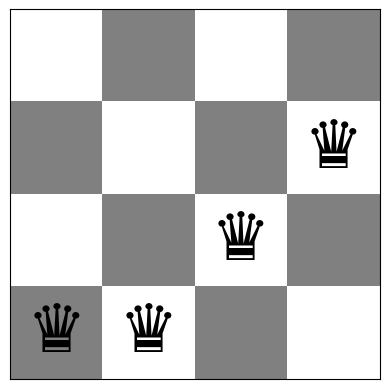

Queens (left to right) are at rows: [3 3 2 1]
Number of conflicts: 4


In [4]:
board = random_board(4)

show_board(board)
print(f"Queens (left to right) are at rows: {board}")
print(f"Number of conflicts: {conflicts(board)}")

A board $4 \times 4$ with no conflicts:

Board with 0 conflicts.


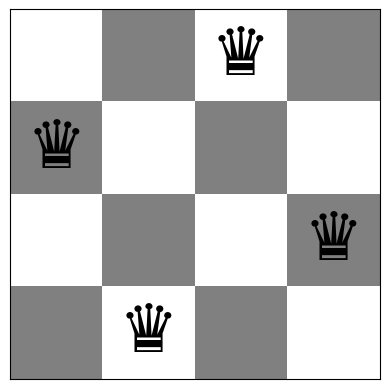

In [5]:
board = [1,3,0,2]
show_board(board)

# Tasks

## General [10 Points]

1. Make sure that you use the latest version of this notebook. Sync your forked repository and pull the latest revision. 
2. Your implementation can use libraries like math, numpy, scipy, but not libraries that implement intelligent agents or complete search algorithms. Try to keep the code simple! In this course, we want to learn about the algorithms and we often do not need to use object-oriented design.
3. You notebook needs to be formatted professionally. 
    - Add additional markdown blocks for your description, comments in the code, add tables and use mathplotlib to produce charts where appropriate
    - Do not show debugging output or include an excessive amount of output.
    - Check that your submitted file is readable and contains all figures.
4. Document your code. Use comments in the code and add a discussion of how your implementation works and your design choices.

## Task 1: Steepest-ascend Hill Climbing Search [20 Points]

Calculate the objective function for all local moves (see definition of local moves above) and always choose the best among all local moves. If there are no local moves that improve the objective, then you have reached a local optimum. 

Bàn cờ đầu : [7 3 6 5 4 4 0 1]  f = 9
Kết quả    : [7 3 6 0 1 4 0 5]  f = 2  (bước = 3, số lần gọi conflicts = 225)
Board with 2 conflicts.


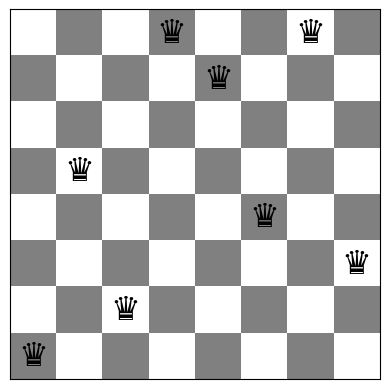

In [6]:
import math, time
import pandas as pd

# Cấu hình thí nghiệm dùng chung: cố định seed để tái lập kết quả
SEED = 1234
np.random.seed(SEED)

def n_neighbors(n):
    """Số láng giềng: mỗi cột có (n-1) hàng khác để chuyển quân hậu tới."""
    return n * (n - 1)


def steepest_ascent(board, max_steps=1000):
    """Steepest-ascent hill climbing.
    Ở mỗi bước: đánh giá TẤT CẢ n(n-1) láng giềng, chọn láng giềng tốt nhất.
    Dừng khi không có láng giềng nào có conflicts nhỏ hơn hẳn trạng thái hiện tại.
    (Bước đi ngang -- plateau -- không được chấp nhận, nên thuật toán luôn dừng.)
    """
    board = np.array(board).copy()
    n = len(board)
    cur = conflicts(board)
    evals, steps = 1, 0
    history = [cur]                      # f theo từng bước leo

    while steps < max_steps:
        best_val, best_move = cur, None
        for col in range(n):
            old = board[col]
            for row in range(n):
                if row == old:
                    continue
                board[col] = row
                val = conflicts(board)
                evals += 1
                if val < best_val:       # strict "<": lấy nước đi tốt nhất, hòa thì giữ nước đầu tiên
                    best_val, best_move = val, (col, row)
            board[col] = old             # hoàn nguyên sau khi thử cột này
        if best_move is None:            # cực trị cục bộ (hoặc đã tối ưu)
            break
        board[best_move[0]] = best_move[1]
        cur = best_val
        steps += 1
        history.append(cur)

    return {"board": board, "f": cur, "steps": steps, "evals": evals, "history": history}


# Thử nghiệm nhanh
np.random.seed(SEED)
b0 = random_board(8)
res = steepest_ascent(b0)
print(f"Bàn cờ đầu : {b0}  f = {conflicts(b0)}")
print(f"Kết quả    : {res['board']}  f = {res['f']}  (bước = {res['steps']}, số lần gọi conflicts = {res['evals']})")
show_board(res["board"], fontsize=24)


**Mô tả & nhận xét (Task 1 – Steepest-ascent).**
Trạng thái là vector `board` (cột *i* có đúng một quân hậu ở hàng `board[i]`); mỗi bàn cờ có **n(n−1)** láng giềng (đổi hàng của một quân hậu). Mỗi bước ta gọi `conflicts()` cho cả n(n−1) láng giềng (n = 8 → 56 lần/bước) rồi chọn láng giềng tốt nhất; dừng khi không còn láng giềng nào *nhỏ hơn hẳn* f hiện tại. Ví dụ trên dừng ở f = 2 sau 3 bước: đó là **cực trị cục bộ** – mọi nước đi 1 quân đều không làm f giảm, dù chưa phải nghiệm.

## Task 2: Inefficient Stochastic Hill Climbing [10 Points]

Modify the algorithm for steepest-ascend hill climbing by choosing randomly from among all uphill moves till you have reached a local optimum.

In [7]:
def stochastic_hc_all_moves(board, max_steps=1000):
    """Stochastic hill climbing 'kém hiệu quả' (Inefficient):
    liệt kê MỌI nước đi cải thiện, rồi chọn ngẫu nhiên đều một nước trong số đó.
    """
    board = np.array(board).copy()
    n = len(board)
    cur = conflicts(board)
    evals, steps = 1, 0
    history = [cur]

    while steps < max_steps:
        improving = []                           # danh sách (cột, hàng, f mới)
        for col in range(n):
            old = board[col]
            for row in range(n):
                if row == old:
                    continue
                board[col] = row
                val = conflicts(board)
                evals += 1
                if val < cur:
                    improving.append((col, row, val))
            board[col] = old
        if not improving:                        # không còn nước cải thiện -> cực trị cục bộ
            break
        col, row, val = improving[np.random.randint(len(improving))]
        board[col] = row
        cur = val
        steps += 1
        history.append(cur)

    return {"board": board, "f": cur, "steps": steps, "evals": evals, "history": history}


np.random.seed(SEED)
b0 = random_board(8)
res = stochastic_hc_all_moves(b0)
print(f"Bàn cờ đầu: f = {conflicts(b0)} -> f cuối = {res['f']}  (bước = {res['steps']}, số lần gọi conflicts = {res['evals']})")


Bàn cờ đầu: f = 9 -> f cuối = 0  (bước = 6, số lần gọi conflicts = 393)


**Mô tả & nhận xét (Task 2).**
Khác Task 1 ở chỗ: thay vì lấy nước tốt nhất, ta gom *mọi* nước làm giảm f rồi chọn ngẫu nhiên đều. Chi phí mỗi bước vẫn là n(n−1) lần gọi `conflicts()` nên rất tốn; bù lại đường đi đa dạng hơn (chạy lại từ cùng bàn cờ có thể cho kết quả khác nhau) và đôi khi thoát được những bẫy mà steepest-ascent rơi vào.

__Important note:__ This is a very expensive algorithm since it has to calculate the objective function (number of conflicts) for all possible moves. The next algorithm produces the same result, but with much less computational cost.

## Task 3: Efficient Stochastic Hill Climbing [20 Points]

Stochastic hill climbing is in practice always implemented in the following way: 

1. Generate only a single random local neighbor at a time.
2. Accept the move if it has a better objective function value than the current state. 
3. Repeat till a stopping criterion is met.

This is very efficient if each state has many possible successor states. This method is called "First-choice hill climbing" in the textbook and in practice this is just called "Stochastic Hill Climbing."

__Notes:__ 

* Detecting local optima is tricky since you never calculate the objective function for all local moves! A popular option is to stop if you were not able to improve the objective function during the last $x$ tries. You will need to argue what the right number for $x$ is. It will depend on the size of the board. Hint: You are sampling random local moves from the set of all possible moves with replacement and you want to make sure that you trie almost all before you stop.

In [8]:
def random_neighbor_move(board):
    """Sinh MỘT láng giềng ngẫu nhiên đều: chọn cột, rồi chọn hàng khác hàng hiện tại."""
    n = len(board)
    col = np.random.randint(n)
    row = np.random.randint(n - 1)
    if row >= board[col]:                        # bỏ qua hàng hiện tại để chọn đều trong n-1 hàng còn lại
        row += 1
    return col, row


def patience_for(n, c=2.0):
    """Số lần thử liên tiếp không cải thiện trước khi kết luận 'cực trị cục bộ'.
    Lấy mẫu CÓ hoàn lại từ m = n(n-1) láng giềng (bài toán coupon collector):
    sau k = m(ln m + c) lần thử, số láng giềng chưa từng được thử kỳ vọng ~ e^-c (c=2 -> ~0.14),
    nghĩa là gần như đã thử hết láng giềng.
    """
    m = n_neighbors(n)
    return int(math.ceil(m * (math.log(m) + c)))


def stochastic_hc(board, patience=None, max_iter=100000):
    """Stochastic / First-choice hill climbing (hiệu quả): sinh từng láng giềng, nhận nếu tốt hơn."""
    board = np.array(board).copy()
    n = len(board)
    if patience is None:
        patience = patience_for(n)
    cur = conflicts(board)
    evals, iters, fails = 1, 0, 0
    history = [cur]                              # f sau MỖI lần thử (kể cả lần bị từ chối)

    while iters < max_iter and cur > 0 and fails < patience:
        col, row = random_neighbor_move(board)
        old = board[col]
        board[col] = row
        val = conflicts(board)
        evals += 1
        iters += 1
        if val < cur:                            # cải thiện -> nhận, reset bộ đếm thất bại
            cur, fails = val, 0
        else:                                    # không cải thiện -> hoàn nguyên
            board[col] = old
            fails += 1
        history.append(cur)

    return {"board": board, "f": cur, "steps": iters, "evals": evals, "history": history}


print("Patience theo kích thước bàn cờ:", {n: patience_for(n) for n in (4, 8, 12, 16, 20)})

np.random.seed(SEED)
b0 = random_board(8)
res = stochastic_hc(b0)
print(f"Bàn cờ đầu: f = {conflicts(b0)} -> f cuối = {res['f']}  (số lần thử = {res['steps']}, gọi conflicts = {res['evals']})")


Patience theo kích thước bàn cờ: {4: 54, 8: 338, 12: 909, 16: 1796, 20: 3018}
Bàn cờ đầu: f = 9 -> f cuối = 1  (số lần thử = 388, gọi conflicts = 389)


**Mô tả & nhận xét (Task 3 – Efficient Stochastic / First-choice).**
Mỗi lần chỉ sinh **một** láng giềng ngẫu nhiên và nhận nếu f giảm → mỗi vòng lặp chỉ tốn 1 lần gọi `conflicts()`.
*Tiêu chí dừng:* vì không bao giờ duyệt hết láng giềng nên dùng “patience”: dừng nếu `x` lần thử liên tiếp không cải thiện. Lấy mẫu có hoàn lại từ m = n(n−1) láng giềng là bài toán *coupon collector*: sau k = m(ln m + c) lần thử, số láng giềng chưa được thử kỳ vọng ≈ e^(−c). Chọn c = 2 (≈ 14%, tức gần như đã thử hết) ta được x = ⌈m(ln m + 2)⌉ = 54 (n=4), 338 (n=8), 909 (n=12), 1796 (n=16), 3018 (n=20).

## Task 4: Hill Climbing Search with Random Restarts [10 Points]

Hill climbing will often end up in local optima. Restart the each of the three hill climbing algorithm up to 100 times with a random board to find a better (hopefully optimal) solution. Note that restart just means to run the algorithm several times starting with a new random board.

,Thuật toán + Random Restart (n=8),% tìm được f=0 (≤100 lần),Số restart TB,Số lần gọi conflicts TB,Thời gian TB (ms)
0,Steepest-ascent,100.0,6.8,1628.9,15.6
1,Stochastic (all moves),100.0,7.3,2463.9,21.1
2,Stochastic (random neighbor),100.0,7.2,2569.5,32.8


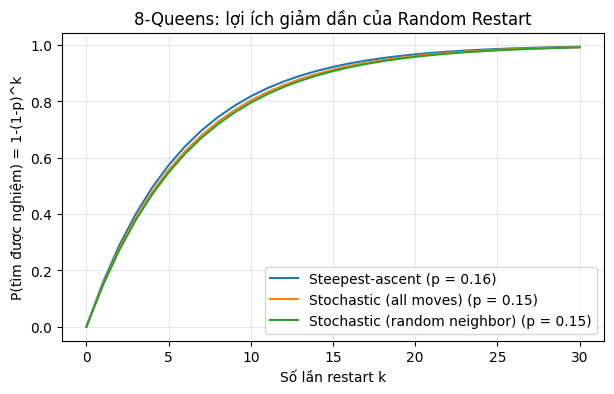

In [9]:
def random_restart(algorithm, n, max_restarts=100, **kwargs):
    """Chạy lại `algorithm` từ bàn cờ ngẫu nhiên mới tối đa max_restarts lần.
    Dừng sớm nếu tìm được nghiệm (f = 0). Trả về kết quả tốt nhất, số lần khởi động, tổng số lần gọi conflicts."""
    best, total_evals = None, 0
    for r in range(1, max_restarts + 1):
        res = algorithm(random_board(n), **kwargs)
        total_evals += res["evals"]
        if best is None or res["f"] < best["f"]:
            best = res
        if best["f"] == 0:
            break
    return {**best, "restarts": r, "evals": total_evals}


algos_hc = {
    "Steepest-ascent": steepest_ascent,
    "Stochastic (all moves)": stochastic_hc_all_moves,
    "Stochastic (random neighbor)": stochastic_hc,
}

# Mỗi thuật toán + restart được lặp 30 lần trên n = 8 để ước tính độ ổn định
np.random.seed(SEED)
rows = []
for name, alg in algos_hc.items():
    out = []
    for _ in range(30):
        t0 = time.perf_counter()
        r = random_restart(alg, 8, max_restarts=100)
        out.append((r["f"], r["restarts"], r["evals"], (time.perf_counter() - t0) * 1e3))
    out = np.array(out)
    rows.append({"Thuật toán + Random Restart (n=8)": name,
                 "% tìm được f=0 (≤100 lần)": 100 * np.mean(out[:, 0] == 0),
                 "Số restart TB": out[:, 1].mean(),
                 "Số lần gọi conflicts TB": out[:, 2].mean(),
                 "Thời gian TB (ms)": out[:, 3].mean()})
display(pd.DataFrame(rows).round(1))

# Xác suất thành công của MỘT lần chạy (không restart) -> xác suất sau k lần restart: 1-(1-p)^k
np.random.seed(SEED)
p_single = {}
for name, alg in algos_hc.items():
    p_single[name] = np.mean([alg(random_board(8))["f"] == 0 for _ in range(300)])

ks = np.arange(0, 31)
plt.figure(figsize=(7, 4))
for name, p in p_single.items():
    plt.plot(ks, 1 - (1 - p) ** ks, label=f"{name} (p = {p:.2f})")
plt.xlabel("Số lần restart k"); plt.ylabel("P(tìm được nghiệm) = 1-(1-p)^k")
plt.title("8-Queens: lợi ích giảm dần của Random Restart"); plt.legend(); plt.grid(alpha=.3)
plt.show()


**Nhận xét (Task 4 – Random Restart).**
Với n = 8, một lần chạy đơn lẻ của cả ba biến thể Hill Climbing chỉ tìm được nghiệm khoảng 14–16% (xem Task 6), nhưng chỉ cần **~7 lần restart** là cả ba đều đạt 100% trong giới hạn 100 lần. Nếu xác suất thành công một lần là *p* thì sau *k* lần restart là 1−(1−p)^k: đồ thị cho thấy đường cong bão hoà rất nhanh (lợi ích **giảm dần** – sau khoảng 20–30 lần restart xác suất đã gần 1, restart thêm hầu như không cải thiện thêm mà chỉ tốn thời gian). Restart cũng chỉ hiệu quả khi *p* không quá nhỏ: với n lớn p giảm mạnh nên số restart cần thiết tăng theo.

## Task 5: Simulated Annealing [10 Points]

Simulated annealing is a form of efficient stochastic hill climbing that avoid local optima by also allowing downhill moves with a probability proportional to a temperature. The temperature is decreased in every iteration following an annealing schedule. You have to experiment with the annealing schedule (Google to find guidance on this).


1. Implement simulated annealing for the n-Queens problem.
2. Create a visualization of the search process (a line chart of how the number if conflict changes as the algorithm progresses).
3. Use this visualization for experiments with different choices for the annealing schedule and discuss what you have learned.

f đầu = 9 -> f cuối = 0 sau 1079 vòng lặp


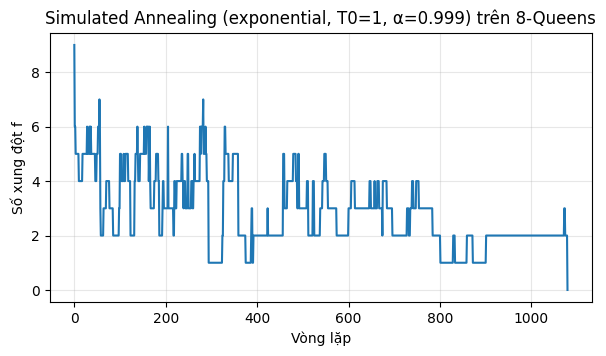

,"Lịch (T0=1, n=8)",% thành công,f cuối TB,Vòng lặp TB,Thời gian TB (ms)
0,exp α=0.99,96.0,0.04,1488.76,20.16
1,exp α=0.999,98.0,0.02,1512.71,21.51
2,exp α=0.9995,99.0,0.01,1695.75,22.96
3,linear,100.0,0.00,3497.17,47.48
4,fast,96.0,0.04,1349.65,19.84
5,logarithmic,99.0,0.01,828.36,12.39


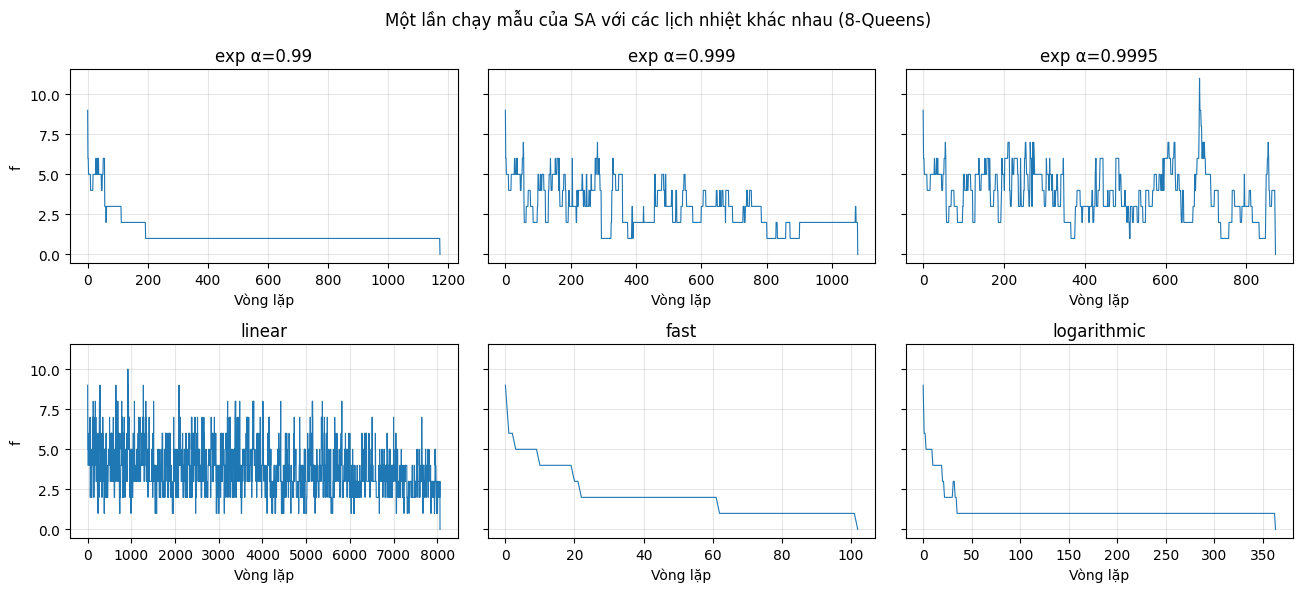

,T0,% thành công,f cuối TB,Vòng lặp TB
0,0.1,97.0,0.03,1350.42
1,0.3,100.0,0.00,535.98
2,1.0,98.0,0.02,1512.71
3,3.0,99.0,0.01,2223.44
4,10.0,99.0,0.01,3528.63


In [10]:
def temperature_exponential(t, T0, alpha): return T0 * alpha ** t
def temperature_linear(t, T0, eta):        return max(T0 - eta * t, 1e-9)       # chặn dưới để T > 0
def temperature_fast(t, T0):                return T0 / (1 + t)
def temperature_logarithmic(t, T0):         return T0 / np.log1p(t)             # chỉ xác định với t > 0


def simulated_annealing(board, T0=1.0, schedule="exponential", alpha=0.999, max_iter=20000):
    """Simulated Annealing cho n-Queens.
    - Láng giềng: một quân hậu chuyển sang hàng khác trong cùng cột (ngẫu nhiên đều).
    - Delta = f(mới) - f(hiện tại). Delta<0: nhận; ngược lại nhận với xác suất exp(-Delta/T).
    - Dừng khi f = 0 hoặc hết ngân sách max_iter vòng lặp.
    """
    board = np.array(board).copy()
    n = len(board)
    cur = conflicts(board)
    best_board, best_f = board.copy(), cur
    eta = T0 / max_iter                          # hệ số cho lịch tuyến tính: T về ~0 đúng lúc hết ngân sách
    evals, history, temps = 1, [cur], []

    for t in range(1, max_iter + 1):             # t bắt đầu từ 1 (lịch logarithmic cần t > 0)
        if cur == 0:
            break
        if schedule == "exponential": T = temperature_exponential(t, T0, alpha)
        elif schedule == "linear":    T = temperature_linear(t, T0, eta)
        elif schedule == "fast":      T = temperature_fast(t, T0)
        elif schedule == "logarithmic": T = temperature_logarithmic(t, T0)
        else: raise ValueError(schedule)
        temps.append(T)

        col, row = random_neighbor_move(board)
        old = board[col]
        board[col] = row
        val = conflicts(board)
        evals += 1
        delta = val - cur
        if delta < 0 or np.random.rand() < math.exp(-delta / T):
            cur = val                            # chấp nhận (kể cả bước xấu hơn)
            if cur < best_f:
                best_f, best_board = cur, board.copy()
        else:
            board[col] = old                     # từ chối -> hoàn nguyên
        history.append(cur)

    return {"board": best_board, "f": best_f, "steps": len(history) - 1, "evals": evals,
            "history": history, "temps": temps}


# --- (1)+(2) Một lần chạy minh hoạ trên 8-Queens và đồ thị số xung đột theo vòng lặp
np.random.seed(SEED)
b0 = random_board(8)
res = simulated_annealing(b0, T0=1.0, schedule="exponential", alpha=0.999)
print(f"f đầu = {conflicts(b0)} -> f cuối = {res['f']} sau {res['steps']} vòng lặp")
plt.figure(figsize=(7, 3.5))
plt.plot(res["history"]); plt.xlabel("Vòng lặp"); plt.ylabel("Số xung đột f")
plt.title("Simulated Annealing (exponential, T0=1, α=0.999) trên 8-Queens"); plt.grid(alpha=.3); plt.show()

# --- (3) So sánh lịch giảm nhiệt: 100 lần chạy / cấu hình, cùng ngân sách 20000 vòng
configs = {
    "exp α=0.99":   dict(schedule="exponential", alpha=0.99),
    "exp α=0.999":  dict(schedule="exponential", alpha=0.999),
    "exp α=0.9995": dict(schedule="exponential", alpha=0.9995),
    "linear":       dict(schedule="linear"),
    "fast":         dict(schedule="fast"),
    "logarithmic":  dict(schedule="logarithmic"),
}
rows, curves = [], {}
for name, cfg in configs.items():
    np.random.seed(SEED)
    out = []
    for k in range(100):
        t0 = time.perf_counter()
        r = simulated_annealing(random_board(8), T0=1.0, **cfg)
        out.append((r["f"], r["steps"], (time.perf_counter() - t0) * 1e3))
        if k == 0: curves[name] = r["history"]
    out = np.array(out)
    rows.append({"Lịch (T0=1, n=8)": name, "% thành công": 100 * np.mean(out[:, 0] == 0),
                 "f cuối TB": out[:, 0].mean(), "Vòng lặp TB": out[:, 1].mean(), "Thời gian TB (ms)": out[:, 2].mean()})
sched_table = pd.DataFrame(rows).round(2)
display(sched_table)

fig, axes = plt.subplots(2, 3, figsize=(13, 6), sharey=True)
for ax, (name, h) in zip(axes.ravel(), curves.items()):
    ax.plot(h, lw=.8); ax.set_title(name); ax.set_xlabel("Vòng lặp"); ax.grid(alpha=.3)
axes[0, 0].set_ylabel("f"); axes[1, 0].set_ylabel("f")
plt.suptitle("Một lần chạy mẫu của SA với các lịch nhiệt khác nhau (8-Queens)"); plt.tight_layout(); plt.show()

# --- Ảnh hưởng của nhiệt độ đầu T0 (lịch exponential, alpha=0.999)
rows = []
for T0 in (0.1, 0.3, 1.0, 3.0, 10.0):
    np.random.seed(SEED)
    out = np.array([[(r := simulated_annealing(random_board(8), T0=T0, schedule="exponential", alpha=0.999))["f"], r["steps"]]
                    for _ in range(100)])
    rows.append({"T0": T0, "% thành công": 100 * np.mean(out[:, 0] == 0), "f cuối TB": out[:, 0].mean(), "Vòng lặp TB": out[:, 1].mean()})
display(pd.DataFrame(rows).round(2))


**Nhận xét (Task 5 – Simulated Annealing).**
* Bước xấu (Δ>0) được chấp nhận với xác suất e^(−Δ/T). Lúc T lớn SA gần như đi ngẫu nhiên (**khám phá**, đường f dao động mạnh), khi T nhỏ SA hành xử như hill climbing (**khai thác**) – xem đồ thị: f dao động rồi “đóng băng” về 0.
* Cả sáu lịch nhiệt đều đạt 96–100% trên 8-Queens (so với ~15% của hill climbing đơn lẻ). Lịch **tuyến tính** cho 100% nhưng cần nhiều vòng lặp nhất (~3500) vì T vẫn còn lớn gần hết ngân sách; **logarithmic** hội tụ nhanh nhất ở đây (~830 vòng) và **fast** nguội rất nhanh nên có lúc kẹt (96%).
* Lịch nào làm thuật toán chấp nhận bước xấu lâu hơn? Với T0 = 1 và ngưỡng T > 0.217 (xác suất nhận bước Δ=1 còn > 1%): tuyến tính (η nhỏ) và mũ α ≈ 0.999 giữ T cao lâu nhất; fast (T0/(1+t)) nguội nhanh nhất (chỉ vài vòng); logarithmic rơi nhanh ở đầu nhưng có đuôi dài (T còn ~0.1 sau 20 000 vòng) – xem Bài 5 trong `Simulated_Annealing_Schedules.ipynb`.
* Nhiệt độ đầu T0: quá thấp (0.1) → SA gần như hill climbing nên có lúc kẹt (97%); quá cao (10) → mất nhiều vòng lặp ở trạng thái “nóng” (~3500 vòng so với ~540 vòng khi T0 = 0.3). Với hàm mục tiêu có bước nhảy cỡ 1–2 đơn vị, T0 ≈ 0.3–1 là hợp lý. Vì thế bảng so sánh ở Task 6 dùng lịch mũ, T0 = 1, α = 0.999.

## Task 6: Algorithm Behavior Analysis [20 Points]

### Comparison
Compare the algorithm using runtime and objective function values. Use boards of size 4 and 8 to explore how the different algorithms perform. Make sure that you run the algorithms for each board size several times (at least 100 times) with different starting boards and report averages.

Complete the following table

| Algorithm            | Board size | Avg. Run time | Avg. number of conflicts | % of runs ending in optimal solution  |
| -------------------- | ---------- | ------------- | --------------------------------- | - |
| Steepest asc. HC     |     4      |               |                                   |   |
| Ineff. Stochastic HC |     4      |               |                                   |   |
| Efficient Stochastic HC |     4      |               |                                   |   |
| Simulated Annealing  |     4      |               |                                   |   |
| Steepest asc. HC     |     8      |               |                                   |   |
| Ineff. Stochastic HC |     8      |               |                                   |   |
| Efficient Stochastic HC |     8      |               |                                   |   |
| Simulated Annealing  |     8      |               |                                   |   |

Hint: See [Profiling Python Code](../HOWTOs/profiling_code.ipynb) for help about how to measure runtime in Python.

Add the used code here:

In [11]:
# Cấu hình SA dùng cho bảng so sánh: chọn theo kết quả Task 5 (xem bảng ở trên)
SA_CFG = dict(T0=1.0, schedule="exponential", alpha=0.999, max_iter=20000)

compare_algos = {
    "Steepest asc. HC":        lambda b: steepest_ascent(b),
    "Ineff. Stochastic HC":    lambda b: stochastic_hc_all_moves(b),
    "Efficient Stochastic HC": lambda b: stochastic_hc(b),
    "Simulated Annealing":     lambda b: simulated_annealing(b, **SA_CFG),
}

def run_experiment(alg, n, runs=100, seed=SEED):
    """Chạy `alg` `runs` lần từ các bàn cờ ngẫu nhiên khác nhau; trả về các số trung bình."""
    np.random.seed(seed)
    f, tms, its, ev = [], [], [], []
    for _ in range(runs):
        b = random_board(n)
        t0 = time.perf_counter()
        r = alg(b)
        tms.append((time.perf_counter() - t0) * 1e3)
        f.append(r["f"]); its.append(r["steps"]); ev.append(r["evals"])
    f = np.array(f)
    return {"Avg. run time (ms)": np.mean(tms), "Avg. conflicts": f.mean(), "% optimal": 100 * np.mean(f == 0),
            "Avg. iterations": np.mean(its), "Avg. evals": np.mean(ev)}

rows = []
for n in (4, 8):
    for name, alg in compare_algos.items():
        rows.append({"Algorithm": name, "Board size": n, **run_experiment(alg, n, runs=100)})
results_table = pd.DataFrame(rows)
display(results_table.round(3))


,Algorithm,Board size,Avg. run time (ms),Avg. conflicts,% optimal,Avg. iterations,Avg. evals
0,Steepest asc. HC,4,0.138,0.54,48.0,1.59,32.08
1,Ineff. Stochastic HC,4,0.163,0.78,38.0,1.88,35.56
2,Efficient Stochastic HC,4,0.459,0.85,30.0,46.89,47.89
3,Simulated Annealing,4,0.475,0.00,100.0,51.55,52.55
4,Steepest asc. HC,8,1.840,1.25,14.0,3.14,232.84
5,Ineff. Stochastic HC,8,2.920,1.16,14.0,5.19,347.64
6,Efficient Stochastic HC,8,4.287,1.12,16.0,356.32,357.32
7,Simulated Annealing,8,23.642,0.02,98.0,1512.71,1513.71


**Nhận xét bảng kết quả (Task 6 – so sánh, 100 lần chạy, seed = 1234).**
* Cả ba biến thể Hill Climbing đều dừng rất sớm (vài bước leo) nên rất nhanh nhưng thường mắc kẹt ở cực trị cục bộ: chỉ ~14–16% số lần tới nghiệm với n = 8 (và 30–48% với n = 4, vì n = 4 chỉ có 2 nghiệm trong 256 bàn cờ).
* **Simulated Annealing** đạt ~98–100% nghiệm tối ưu nhưng chậm hơn (~16 ms so với 1–4 ms với n = 8) vì phải chạy hàng nghìn vòng lặp: đánh đổi **chất lượng ↔ chi phí tính toán**.
* Steepest-ascent mất 1 bước = n(n−1) lần gọi `conflicts()` nhưng chỉ cần ít bước; Efficient Stochastic cần nhiều vòng lặp (~350) nhưng mỗi vòng chỉ 1 lần gọi, nên tổng số lần gọi tương đương Ineff. Stochastic (~350) và chỉ hơn steepest (~230). Thời gian thực tế của Efficient Stochastic cao hơn vì chi phí khởi tạo số ngẫu nhiên Python trong mỗi vòng lặp.

### Algorithm Convergence

For each algorithm implemented, describe the typical convergence pattern (fast initial improvement vs. steady progress).
Include a plot showing the objective function value over iterations for one representative run of each algorithm on the 8-queens problem.
Explain which algorithms exhibit plateaus or getting stuck in local optima most frequently.

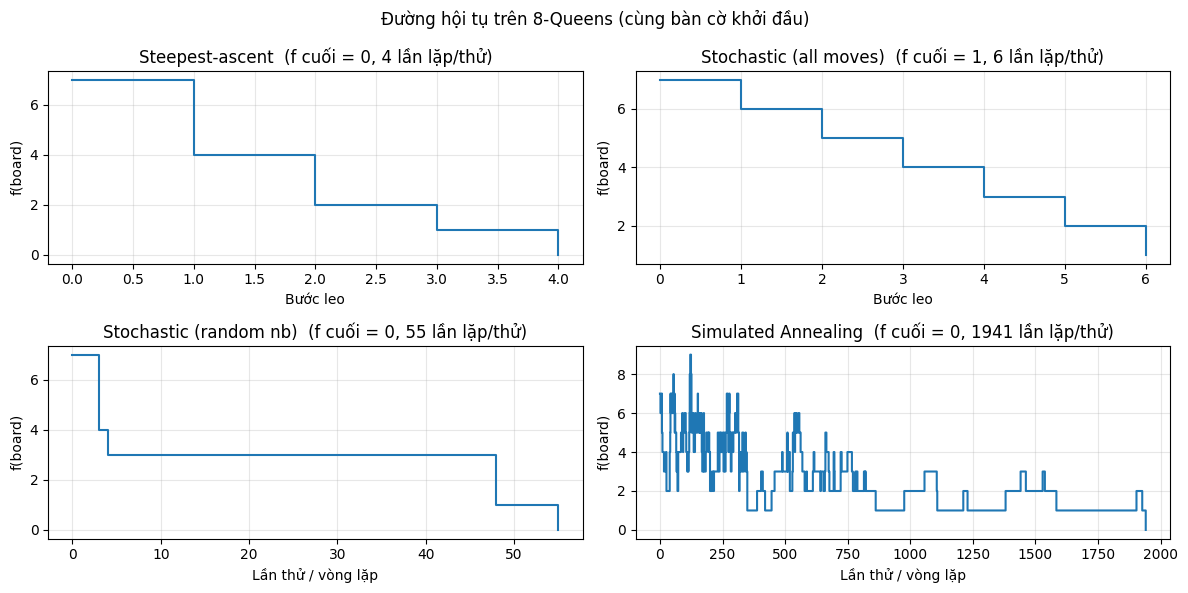

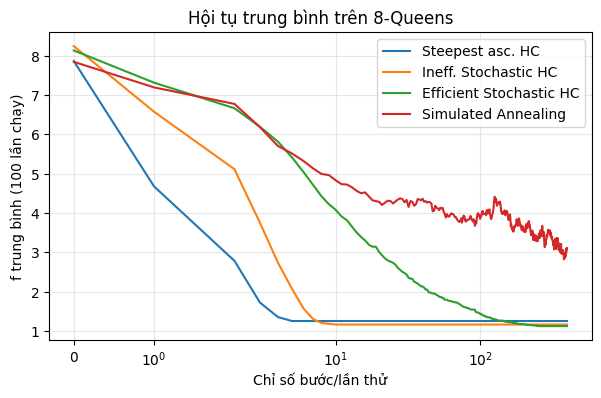

,Steepest asc. HC,Ineff. Stochastic HC,Efficient Stochastic HC,Simulated Annealing
% mắc kẹt ở cực trị cục bộ (f>0),84.0,87.0,87.0,1.0


In [12]:
# Một lần chạy đại diện trên 8-Queens: cả 4 thuật toán xuất phát từ CÙNG một bàn cờ
np.random.seed(7)
b0 = random_board(8)
runs = {
    "Steepest-ascent":        steepest_ascent(b0),
    "Stochastic (all moves)": stochastic_hc_all_moves(b0),
    "Stochastic (random nb)": stochastic_hc(b0),
    "Simulated Annealing":    simulated_annealing(b0, **SA_CFG),
}
fig, axes = plt.subplots(2, 2, figsize=(12, 6))
for ax, (name, r) in zip(axes.ravel(), runs.items()):
    drawstyle = "steps-post"
    ax.plot(r["history"], drawstyle=drawstyle)
    ax.set_title(f"{name}  (f cuối = {r['f']}, {len(r['history'])-1} lần lặp/thử)")
    ax.set_xlabel("Bước leo" if "Steepest" in name or "all moves" in name else "Lần thử / vòng lặp")
    ax.set_ylabel("f(board)"); ax.grid(alpha=.3)
plt.suptitle("Đường hội tụ trên 8-Queens (cùng bàn cờ khởi đầu)"); plt.tight_layout(); plt.show()

# Đường hội tụ TRUNG BÌNH trên 100 bàn cờ để thấy xu hướng chung (trục x: số lần gọi conflicts)
def mean_curve(alg, runs=100, L=400):
    np.random.seed(SEED)
    H = []
    for _ in range(runs):
        h = alg(random_board(8))["history"]
        h = h[:L] + [h[-1]] * max(0, L - len(h))    # dừng sớm -> giữ nguyên giá trị cuối
        H.append(h)
    return np.mean(H, axis=0)

plt.figure(figsize=(7, 4))
for name, alg in compare_algos.items():
    plt.plot(mean_curve(alg), label=name)
plt.xlabel("Chỉ số bước/lần thử"); plt.ylabel("f trung bình (100 lần chạy)")
plt.title("Hội tụ trung bình trên 8-Queens"); plt.legend(); plt.grid(alpha=.3); plt.xscale("symlog"); plt.show()

stuck = pd.DataFrame({name: [np.mean([alg(random_board(8))["f"] > 0 for _ in range(100)]) * 100]
                      for name, alg in compare_algos.items()}, index=["% mắc kẹt ở cực trị cục bộ (f>0)"]).round(1)
display(stuck)


**Nhận xét hội tụ.**
* *Steepest-ascent / Stochastic (all moves):* giảm f mạnh ở 1–2 bước đầu (nước đi tốt nhất / ngẫu nhiên trong các nước tốt) rồi dừng sớm – đồ thị bậc thang ngắn.
* *Efficient Stochastic:* các bước cải thiện thưa thớt; có những đoạn **bình nguyên dài** (f không đổi nhiều chục lần thử) vì phần lớn láng giềng không tốt hơn; patience quyết định lúc dừng.
* *Simulated Annealing:* ban đầu f **dao động** (chấp nhận bước xấu khi T cao), sau đó giảm dần và ổn định về 0; đây là thuật toán duy nhất cải thiện được ở giai đoạn sau.
* Hiện tượng mắc kẹt/dừng sớm: cả ba Hill Climbing mắc kẹt ở 84–87% số lần chạy (n = 8), SA chỉ ~1%.

### Problem Size Scalability

Create a log-log plot showing how runtime scales with board size ($n=4, 8, 12, 16, 20$) for at least two algorithms.
Estimate the empirical time complexity (Big O) for each algorithm based on your results.
Identify which algorithm scales best for large problem sizes and explain why.

Algorithm,Efficient Stochastic HC,Simulated Annealing,Steepest asc. HC
n,,,
4,0.41,0.60,0.23
8,4.36,16.46,2.80
12,19.63,49.90,8.57
16,45.62,95.51,25.16
20,87.27,110.50,58.24


Algorithm,Efficient Stochastic HC,Simulated Annealing,Steepest asc. HC
n,,,
4,30.0,100.0,65.0
8,15.0,100.0,5.0
12,5.0,100.0,5.0
16,5.0,100.0,5.0
20,0.0,100.0,0.0


Steepest asc. HC         : time ~ n^3.37
Efficient Stochastic HC  : time ~ n^3.36
Simulated Annealing      : time ~ n^3.29


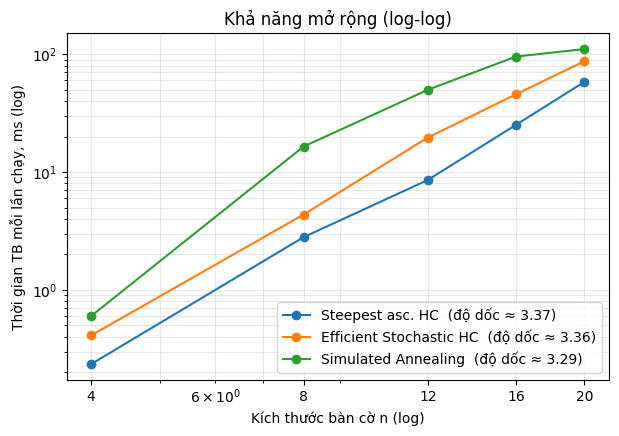

In [13]:
# Khảo sát khả năng mở rộng: n = 4, 8, 12, 16, 20 ; 3 thuật toán ; 20 lần chạy / điểm
sizes = [4, 8, 12, 16, 20]
scal_algos = {
    "Steepest asc. HC":        lambda b: steepest_ascent(b),
    "Efficient Stochastic HC": lambda b: stochastic_hc(b),
    "Simulated Annealing":     lambda b: simulated_annealing(b, **SA_CFG),
}
rows = []
for name, alg in scal_algos.items():
    for n in sizes:
        r = run_experiment(alg, n, runs=20)
        rows.append({"Algorithm": name, "n": n, "time_ms": r["Avg. run time (ms)"], "% optimal": r["% optimal"], "evals": r["Avg. evals"]})
scal = pd.DataFrame(rows)
display(scal.pivot(index="n", columns="Algorithm", values="time_ms").round(2))
display(scal.pivot(index="n", columns="Algorithm", values="% optimal").round(0))

plt.figure(figsize=(7, 4.5))
for name in scal_algos:
    d = scal[scal.Algorithm == name]
    slope, intercept = np.polyfit(np.log(d.n), np.log(d.time_ms), 1)    # time ≈ C * n^slope
    plt.loglog(d.n, d.time_ms, "o-", label=f"{name}  (độ dốc ≈ {slope:.2f})")
    print(f"{name:25s}: time ~ n^{slope:.2f}")
plt.xlabel("Kích thước bàn cờ n (log)"); plt.ylabel("Thời gian TB mỗi lần chạy, ms (log)")
plt.title("Khả năng mở rộng (log-log)"); plt.legend(); plt.grid(alpha=.3, which="both"); plt.xticks(sizes, sizes); plt.show()


**Nhận xét khả năng mở rộng (n = 4…20, 20 lần chạy/điểm).**
Độ dốc trên đồ thị log-log ước lượng bậc tăng trưởng thực nghiệm: Steepest ≈ n^3.3–3.8, Efficient Stochastic ≈ n^3.3–3.4, SA ≈ n^3.2–3.4 (dao động nhẹ giữa các lần chạy do nhiễu thời gian).
* Steepest: mỗi bước gọi n(n−1) = O(n²) lần `conflicts()` (mỗi lần O(n)), số bước tăng theo n ⇒ lý thuyết ~O(n⁴); thực nghiệm ~n^3.7 phù hợp.
* Efficient Stochastic và SA: mỗi vòng lặp 1 lần `conflicts()` = O(n); số vòng lặp cần thiết tăng thêm theo n (patience ~ n² log n với HC) nên tổng cỡ n³–n⁴.
* **Lưu ý:** thời gian của Hill Climbing là thời gian tới lúc *mắc kẹt* chứ không phải tới lúc giải xong (tỉ lệ thành công tụt về 0–5% khi n ≥ 12), trong khi SA luôn tìm được nghiệm (100% với mọi n khảo sát). Vì vậy **SA mở rộng tốt nhất về chất lượng** (cùng ngân sách 20 000 vòng vẫn giải được n = 20), còn Steepest nhanh nhất theo thời gian nhưng cho nghiệm kém.

## Advanced task: Exploring other Local Moves Operators

* __Graduate students__ need to complete this task [10 points]
* __Undergraduate students__ can attempt this as a bonus task [max +5 bonus points].

### Move Operator Implementation 

Implement the following local move operators:

* Single-step move: Move one queen only one square up or down at a time
* Column swap: Exchange the positions of queens in two randomly selected columns
* Dual-queen move: Select two queens and move both simultaneously
* Adaptive move: Design your own operator that adapts which local move it uses based on the current state (e.g., focuses on queens with most conflicts or randomly chooses one of the moves above)

### Experimental Analysis

Using the 8-Queens and 12-Queens problems: Run your __Efficient Stochastic Hill Climbing__ implementation with each move operator 100 times.

For each operator, create a visualization showing:

* Average solution quality over iterations
* Distribution of final solution qualities
* Average time to solution for successful runs

### Discussion

Describe what you have learned from the experiments. Which operator works best for which situation and why?

,n,Toán tử,% tối ưu,f cuối TB,Thời gian TB tới nghiệm (ms)
0,8,Single-step,0.0,3.51,NaN
1,8,Column swap,1.0,4.43,1.11
2,8,Dual-queen,25.0,0.77,23.53
3,8,Adaptive,26.0,0.92,8.43
4,8,Column swap (khởi đầu hoán vị),36.0,0.73,0.67
5,12,Single-step,0.0,5.50,NaN
6,12,Column swap,0.0,6.77,NaN
7,12,Dual-queen,2.0,1.45,46.59
8,12,Adaptive,13.0,1.37,16.67
9,12,Column swap (khởi đầu hoán vị),24.0,0.88,2.97


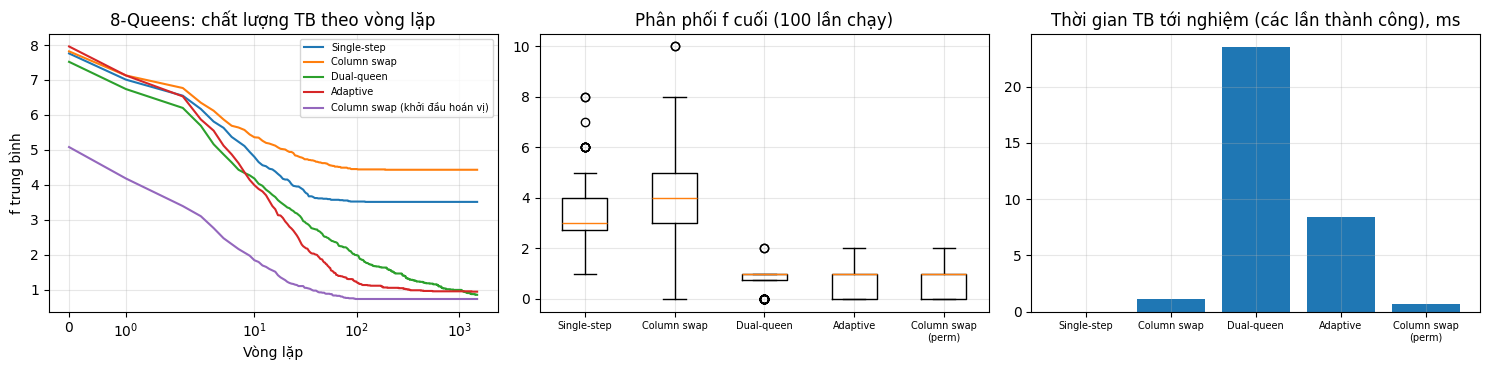

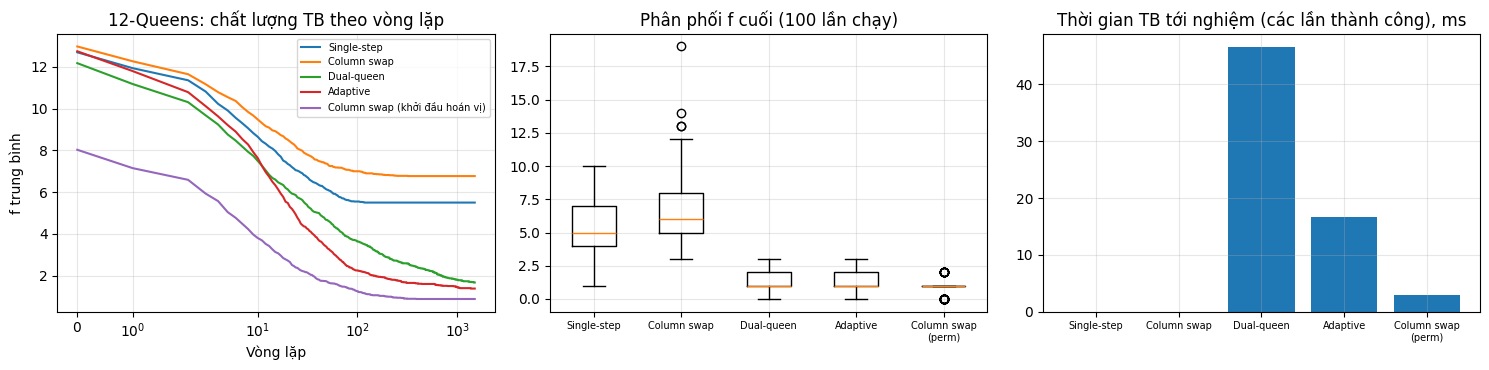

In [14]:
# ---- Toán tử di chuyển: mỗi hàm nhận board, trả về BẢN SAO bàn cờ láng giềng ----
def op_single_step(board):
    """Dịch MỘT quân hậu lên/xuống đúng 1 ô (không ra ngoài bàn cờ). |N| = 2n-2."""
    b = board.copy(); n = len(b)
    col = np.random.randint(n)
    step = np.random.choice([-1, 1])
    if not 0 <= b[col] + step < n: step = -step
    b[col] += step
    return b

def op_column_swap(board):
    """Hoán đổi hàng của hai cột ngẫu nhiên. |N| = n(n-1)/2. Giữ nguyên tập hợp các hàng."""
    b = board.copy(); n = len(b)
    i, j = np.random.choice(n, 2, replace=False)
    b[i], b[j] = b[j], b[i]
    return b

def op_dual_queen(board):
    """Chọn hai cột, chuyển ĐỒNG THỜI cả hai quân hậu sang hàng mới ngẫu nhiên. |N| ~ (n(n-1))^2 / 2."""
    b = board.copy(); n = len(b)
    for col in np.random.choice(n, 2, replace=False):
        row = np.random.randint(n - 1)
        b[col] = row + 1 if row >= b[col] else row
    return b

def queen_conflicts(board):
    """Số quân hậu khác mà mỗi quân hậu đang tấn công (cùng hàng hoặc cùng đường chéo)."""
    n = len(board); idx = np.arange(n)
    same_row = board[:, None] == board[None, :]
    same_diag = np.abs(board[:, None] - board[None, :]) == np.abs(idx[:, None] - idx[None, :])
    return (same_row | same_diag).sum(axis=1) - 1            # trừ chính nó

def op_adaptive(board):
    """Toán tử thích nghi: 70% — chuyển một quân hậu ĐANG XUNG ĐỘT (chọn ngẫu nhiên) sang hàng ngẫu nhiên khác
    (tập trung vào chỗ sai); 30% — chọn ngẫu nhiên một trong ba toán tử trên để vẫn có khả năng khám phá."""
    n = len(board)
    if np.random.rand() < 0.7:
        bad = np.flatnonzero(queen_conflicts(board) > 0)
        if len(bad):
            b = board.copy(); col = np.random.choice(bad)
            row = np.random.randint(n - 1)
            b[col] = row + 1 if row >= b[col] else row
            return b
    return [op_single_step, op_column_swap, op_dual_queen][np.random.randint(3)](board)

OPERATORS = {"Single-step": op_single_step, "Column swap": op_column_swap,
             "Dual-queen": op_dual_queen, "Adaptive": op_adaptive}


def stochastic_hc_op(board, op, patience=2000, max_iter=20000):
    """Efficient Stochastic HC với toán tử `op` bất kỳ (cùng patience cho mọi toán tử để so sánh công bằng)."""
    board = np.array(board).copy()
    cur = conflicts(board); history = [cur]; fails = 0; it = 0
    while it < max_iter and cur > 0 and fails < patience:
        cand = op(board); val = conflicts(cand); it += 1
        if val < cur: board, cur, fails = cand, val, 0
        else: fails += 1
        history.append(cur)
    return {"board": board, "f": cur, "steps": it, "history": history}


def perm_board(n): return np.random.permutation(n)           # bàn cờ không trùng hàng (mỗi hàng đúng 1 quân)

L = 1500                                                    # số vòng lặp hiển thị trên đồ thị trung bình
all_rows, fig_data = [], {}
for n in (8, 12):
    for name, op in list(OPERATORS.items()) + [("Column swap (khởi đầu hoán vị)", op_column_swap)]:
        np.random.seed(SEED)
        gen = perm_board if "hoán vị" in name else random_board
        H, F, T_ok = [], [], []
        for _ in range(100):
            t0 = time.perf_counter()
            r = stochastic_hc_op(gen(n), op)
            dt = (time.perf_counter() - t0) * 1e3
            h = r["history"][:L]; H.append(h + [h[-1]] * (L - len(h)))
            F.append(r["f"])
            if r["f"] == 0: T_ok.append(dt)
        fig_data[(n, name)] = (np.mean(H, axis=0), np.array(F), T_ok)
        all_rows.append({"n": n, "Toán tử": name, "% tối ưu": 100 * np.mean(np.array(F) == 0), "f cuối TB": np.mean(F),
                         "Thời gian TB tới nghiệm (ms)": np.mean(T_ok) if T_ok else np.nan})
adv_table = pd.DataFrame(all_rows).round(2)
display(adv_table)

for n in (8, 12):
    fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
    names = [k[1] for k in fig_data if k[0] == n]
    for name in names:
        mean_h, F, T_ok = fig_data[(n, name)]
        axes[0].plot(mean_h, label=name)
    axes[0].set_xscale("symlog"); axes[0].set_xlabel("Vòng lặp"); axes[0].set_ylabel("f trung bình"); axes[0].set_title(f"{n}-Queens: chất lượng TB theo vòng lặp"); axes[0].legend(fontsize=7)
    axes[1].boxplot([fig_data[(n, nm)][1] for nm in names], tick_labels=[nm.replace(" (khởi đầu hoán vị)", "\n(perm)") for nm in names]); axes[1].set_title("Phân phối f cuối (100 lần chạy)"); axes[1].tick_params(axis="x", labelsize=7)
    tm = [np.mean(fig_data[(n, nm)][2]) if fig_data[(n, nm)][2] else 0 for nm in names]
    axes[2].bar(range(len(names)), tm); axes[2].set_xticks(range(len(names))); axes[2].set_xticklabels([nm.replace(" (khởi đầu hoán vị)", "\n(perm)") for nm in names], fontsize=7)
    axes[2].set_title("Thời gian TB tới nghiệm (các lần thành công), ms")
    for a in axes: a.grid(alpha=.3)
    plt.tight_layout(); plt.show()


**Nhận xét (Advanced – toán tử di chuyển).**
* **Single-step** (|N| = 2n−2) gần như không bao giờ giải được (0%): bước quá nhỏ, dễ kẹt.
* **Column swap** (|N| = n(n−1)/2) từ bàn cờ ngẫu nhiên chỉ ~0–1% vì hoán đổi *không đổi tập các hàng*: nếu bàn cờ khởi đầu có hai quân cùng hàng thì hoán vị không bao giờ sửa được. Nhưng nếu khởi đầu bằng **hoán vị** (mỗi hàng đúng một quân) thì swap lại rất tốt (36% với n=8, 24% với n=12) và nhanh nhất (<3 ms) vì không gian tìm kiếm chỉ còn n! trạng thái.
* **Dual-queen** (lân cận lớn nhất, ~(n(n−1))²/2) tìm được nghiệm tốt hơn (25% / 2%) nhưng chậm, và với n = 12 lân cận quá lớn nên lấy mẫu ngẫu nhiên kém hiệu quả.
* **Adaptive** (tập trung vào quân hậu đang xung đột + trộn các toán tử khác) cho kết quả tốt nhất trong nhóm khởi đầu ngẫu nhiên (26% / 13%) và nhanh hơn Dual-queen ~3–4 lần.
Kết luận: kích thước lân cận lớn → dễ thoát cực trị nhưng mỗi lần thử kém “trúng”; lân cận nhỏ → thử nhanh nhưng dễ kẹt. Toán tử **có định hướng** (adaptive) và **bảo toàn ràng buộc** (swap trên hoán vị) hiệu quả hơn toán tử mù.

## More Things to Do (not for credit)

If the assignment was to easy for yuo then you can think about the following problems. These problems are challenging and not part of this assignment. 

### Implement a Genetic Algorithm for the n-Queens problem

In [15]:
# Code and description go here